Experiment: KNN Classifier-impact of K and distance metrics

Aim: implement a K-Nearest Neighbors classifier and analyze how the value of K and the choice of distance metric affect accuracy.

Theory: KNN classifies a new point by finding the K closest training points and taking a majority vote of their labels. It has no training step, it just stores the data. Because it depends on distances, features should be scaled.

Dataset: Iris (150 samples, 4 features, 3 classes).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

Step 1: Load the data, split into train and test sets (70/30) and scale the features.

In [2]:
X, y = load_iris(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
print(X_train.shape, X_test.shape)

(105, 4) (45, 4)


Step 2: Train a basic KNN classifier with K=5 and the default Euclidean distance.

Test accuracy: 0.9111111111111111


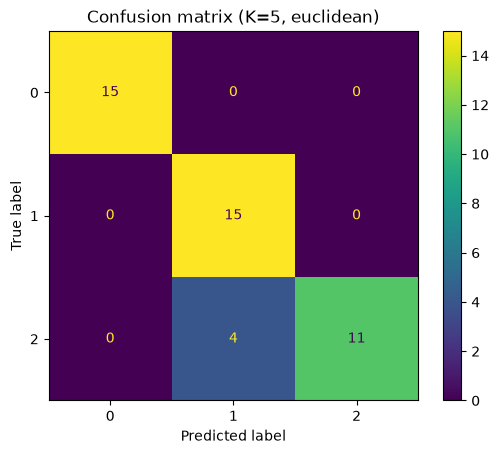

In [3]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
pred = knn.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, pred))

ConfusionMatrixDisplay(confusion_matrix(y_test, pred)).plot()
plt.title("Confusion matrix (K=5, euclidean)")
plt.show()

Step 3: Effect of K. We train the model for K from 1 to 30 and compare train and test accuracy.

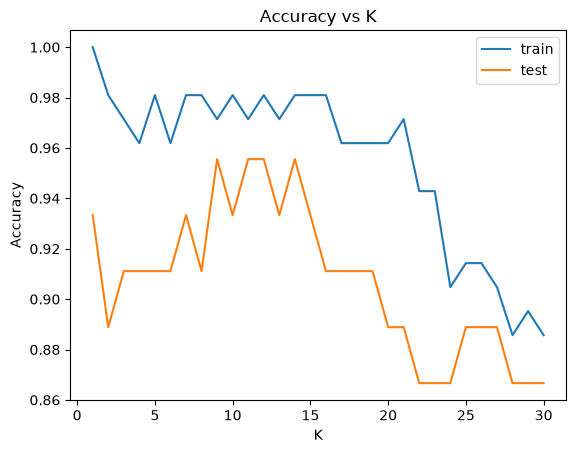

Best K on test set: 9


In [4]:
ks = range(1, 31)
train_acc, test_acc = [], []
for k in ks:
    m = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    train_acc.append(m.score(X_train, y_train))
    test_acc.append(m.score(X_test, y_test))

plt.plot(ks, train_acc, label="train")
plt.plot(ks, test_acc, label="test")
plt.xlabel("K")
plt.ylabel("Accuracy")
plt.title("Accuracy vs K")
plt.legend()
plt.show()

print("Best K on test set:", list(ks)[int(np.argmax(test_acc))])

Observation: with a very small K (like 1) the model fits the training data almost perfectly (train accuracy near 1) but is sensitive to noise, which is overfitting. As K grows, the decision boundary becomes smoother and train accuracy drops. If K becomes too large, the model starts to ignore local structure and underfits. A moderate K usually gives the best test accuracy.

Step 4: Effect of distance metric. We compare four metrics at K=5 using 5-fold cross validation (scaling is done inside the pipeline to avoid data leakage).

euclidean 0.96
manhattan 0.9467
chebyshev 0.9333
cosine 0.8733


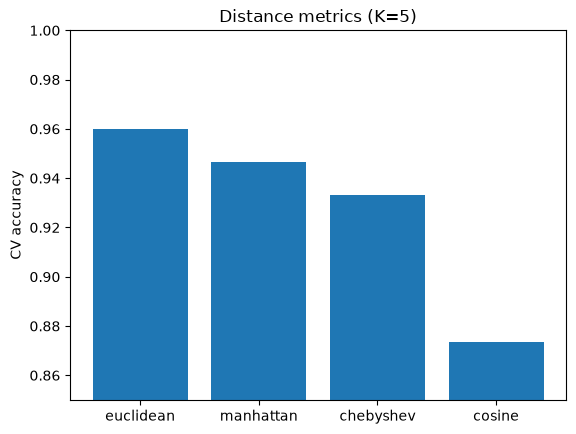

In [5]:
metrics = ["euclidean", "manhattan", "chebyshev", "cosine"]
scores = []
for met in metrics:
    model = make_pipeline(StandardScaler(),
                          KNeighborsClassifier(n_neighbors=5, metric=met))
    scores.append(cross_val_score(model, X, y, cv=5).mean())
    print(met, round(scores[-1], 4))

plt.bar(metrics, scores)
plt.ylim(0.85, 1.0)
plt.ylabel("CV accuracy")
plt.title("Distance metrics (K=5)")
plt.show()

Step 5: K and metric together. Cross validation accuracy for each metric over a range of K.

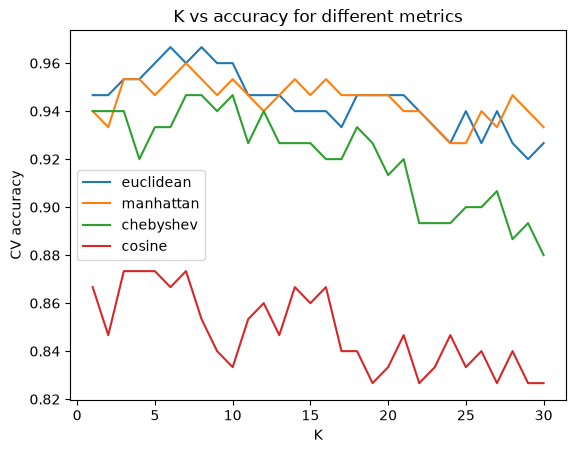

In [6]:
ks = range(1, 31)
for met in metrics:
    accs = []
    for k in ks:
        model = make_pipeline(StandardScaler(),
                              KNeighborsClassifier(n_neighbors=k, metric=met))
        accs.append(cross_val_score(model, X, y, cv=5).mean())
    plt.plot(ks, accs, label=met)

plt.xlabel("K")
plt.ylabel("CV accuracy")
plt.title("K vs accuracy for different metrics")
plt.legend()
plt.show()

Conclusion:
1. K controls the bias-variance tradeoff. Small K gives low bias and high variance (overfitting), large K gives high bias and low variance (underfitting). A moderate K works best.
2. The distance metric changes which points count as neighbors. On Iris the metrics give similar accuracy, but the best choice depends on the dataset. Euclidean is the common default, Manhattan can work better with many features or outliers, and cosine is useful when direction matters more than magnitude.
3. Features must be scaled before using KNN, otherwise features with large ranges dominate the distance.
4. Best K and metric should be chosen with cross validation, not a single test split.